# Retail Store Sales: Data Cleaning & EDA

Cleaning and exploring the **Dirty Retail Store Sales** dataset (12,575 synthetic transactions, 25 customers, 8 product categories).

**What this notebook does**
1. Audits the raw data and shows exactly how it is dirty
2. Cleans it in a dependency-aware order, flagging every estimated value
3. Validates the result with hard assertions
4. Explores sales by category, time, payment method, location, discount and customer

> Excel formulas can't be re-run by a reader, so every cleaning step here is reproducible code.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

RAW_PATH = "../data/raw/retail_store_sales.xlsx"
CLEAN_PATH = "../data/cleaned/retail_store_sales_cleaned.csv"

## 1. Load and audit the raw data

In [2]:
raw = pd.read_csv(RAW_PATH) if RAW_PATH.endswith(".csv") else pd.read_excel(RAW_PATH)
raw.columns = raw.columns.str.strip()
raw = raw.loc[:, ~raw.columns.str.startswith("Unnamed")]   # drop stray empty column

print(f"Rows: {len(raw):,} | Columns: {raw.shape[1]}")
print(f"Duplicate Transaction IDs: {raw['Transaction ID'].duplicated().sum()}")
print(f"Date range: {raw['Transaction Date'].min().date()} to {raw['Transaction Date'].max().date()}")
print(f"Customers: {raw['Customer ID'].nunique()} | Categories: {raw['Category'].nunique()}")

missing = raw.isna().sum().to_frame("missing")
missing["pct"] = (missing["missing"] / len(raw) * 100).round(2)
print("\nMissing values by column:")
print(missing[missing["missing"] > 0].to_string())

Rows: 12,575 | Columns: 11
Duplicate Transaction IDs: 0
Date range: 2022-01-01 to 2025-01-18
Customers: 25 | Categories: 8

Missing values by column:
                  missing    pct
Item                 1213   9.65
Price Per Unit        609   4.84
Quantity              604   4.80
Total Spent           604   4.80
Discount Applied     4199  33.39


### How are the gaps related?
The missingness is not random. Looking at which columns are missing *together* tells us which fixes are possible.

In [3]:
pattern = raw[["Item", "Price Per Unit", "Quantity", "Total Spent"]].isna()
pattern = pattern.value_counts().rename("rows").reset_index()
pattern.columns = ["Item missing", "Price missing", "Quantity missing", "Total missing", "rows"]
print(pattern.to_string(index=False))

 Item missing  Price missing  Quantity missing  Total missing  rows
        False          False             False          False 11362
         True           True             False          False   609
         True          False              True           True   604


**What this shows**
- Whenever **Price** is missing, **Item** is missing too, but Quantity and Total are present. So Price can be recovered exactly as `Total / Quantity`.
- Whenever **Quantity** is missing, **Total Spent** is missing too. So `Total / Price` is impossible for those rows and Quantity has to be **estimated**.
- The remaining missing Items have a known Price, so they can be looked up.

### The price-collision trap
Prices are static per item, but the **same price points are reused across categories** (a 5.0 item exists in every category). Looking an item up by price alone returns the wrong row. The lookup must use **Category + Price**.

In [4]:
known = raw.dropna(subset=["Item", "Price Per Unit"])
ref = known[["Category", "Item", "Price Per Unit"]].drop_duplicates().reset_index(drop=True)

# Integrity of the reference table
assert ref.groupby("Item")["Price Per Unit"].nunique().max() == 1          # one price per item
assert ref.groupby(["Category", "Price Per Unit"])["Item"].nunique().max() == 1   # (Category, Price) -> one item

cats_per_price = ref.groupby("Price Per Unit")["Category"].nunique()
print(f"Reference table: {len(ref)} items across {ref['Category'].nunique()} categories")
print(f"Distinct price points: {len(cats_per_price)}")
print(f"Every price point is shared by {cats_per_price.min()} categories" if cats_per_price.min()==cats_per_price.max() else f"Each price point is shared by {cats_per_price.min()} to {cats_per_price.max()} categories")
print("-> price alone is ambiguous; Category + Price is unique.")

Reference table: 200 items across 8 categories
Distinct price points: 25
Every price point is shared by 8 categories
-> price alone is ambiguous; Category + Price is unique.


## 2. Clean

Fixes depend on each other, so the order matters:

| Step | Column | Method |
|---|---|---|
| 1 | Price Per Unit | `Total Spent / Quantity` where both exist |
| 2 | Item | Lookup on **Category + Price** |
| 3 | Quantity | Item-level average of observed quantities, rounded **up** to a whole number, flagged |
| 4 | Total Spent | `Price x Quantity` (original values are never overwritten) |
| 5 | Discount Applied | Blanks become `UNKNOWN` instead of assuming no discount |

In [5]:
df = raw.copy()
log = {}

# 1. Price from Total / Quantity
m = df["Price Per Unit"].isna() & df["Quantity"].notna() & df["Total Spent"].notna()
df.loc[m, "Price Per Unit"] = (df.loc[m, "Total Spent"] / df.loc[m, "Quantity"]).round(2)
log["Price Per Unit  (Total / Quantity)"] = int(m.sum())

# 2. Item from Category + Price
lookup = ref.set_index(["Category", "Price Per Unit"])["Item"]
m = df["Item"].isna()
keys = pd.MultiIndex.from_frame(df.loc[m, ["Category", "Price Per Unit"]])
df.loc[m, "Item"] = lookup.reindex(keys).to_numpy()
log["Item            (Category + Price lookup)"] = int(m.sum())

# 3. Quantity: item-level average of observed values, rounded up (mirrors ROUNDUP(AVERAGEIF(...), 0))
item_avg = df.groupby("Item")["Quantity"].mean()          # mean skips blanks, like AVERAGEIF
df["Imputed_Flag"] = df["Quantity"].isna()
fill = np.ceil(df["Item"].map(item_avg).round(8))
df["Quantity"] = df["Quantity"].fillna(fill).astype(int)
log["Quantity        (item avg, rounded up, flagged)"] = int(df["Imputed_Flag"].sum())

# 4. Total Spent: check existing values first, then fill
calc_total = df["Price Per Unit"] * df["Quantity"]
existing = df["Total Spent"].notna()
bad = (existing & ~np.isclose(df["Total Spent"], calc_total)).sum()
print(f"Existing Total Spent values that disagree with Price x Quantity: {bad}")
m = df["Total Spent"].isna()
df.loc[m, "Total Spent"] = calc_total[m]
log["Total Spent     (Price x Quantity)"] = int(m.sum())

# 5. Discount: keep unknown as unknown
disc = (df["Discount Applied"].astype("string").str.strip().str.lower()
        .map({"true": "True", "1.0": "True", "1": "True",
              "false": "False", "0.0": "False", "0": "False"}))
log["Discount Applied (blank -> UNKNOWN)"] = int(disc.isna().sum())
df["Discount Applied"] = disc.fillna("UNKNOWN")

print("\nValues filled per step:")
for k, v in log.items():
    print(f"  {k:<42}{v:>6,}")

Existing Total Spent values that disagree with Price x Quantity: 0

Values filled per step:
  Price Per Unit  (Total / Quantity)           609
  Item            (Category + Price lookup)  1,213
  Quantity        (item avg, rounded up, flagged)   604
  Total Spent     (Price x Quantity)           604
  Discount Applied (blank -> UNKNOWN)        4,199


**Why an item-level average, rounded up?** Quantity is missing together with Total Spent, so it can't be recovered, only estimated. The item average mirrors the Excel `AVERAGEIF` approach and ties the estimate to the item. Rounding up gives a whole number but nudges estimates slightly high, and observed quantities are spread almost evenly across 1 to 10, so no estimate is precise. That is why every estimated row is flagged in `Imputed_Flag`, so anyone can exclude or discount those rows.

In [6]:
obs = raw["Quantity"].dropna()
by_item = raw.dropna(subset=["Quantity", "Item"]).groupby("Item")["Quantity"].mean()
print(f"Observed quantity: mean {obs.mean():.2f}, median {obs.median():.0f}, std {obs.std():.2f}")
print(f"Per-item mean quantity ranges {by_item.min():.2f} to {by_item.max():.2f} (noise around a flat distribution)")
print("\nCount of each observed quantity:")
print(obs.astype(int).value_counts().sort_index().to_string())
print("\nImputed quantities (item average, rounded up):")
print(df.loc[df["Imputed_Flag"], "Quantity"].value_counts().sort_index().to_string())

Observed quantity: mean 5.54, median 6, std 2.86
Per-item mean quantity ranges 3.83 to 6.78 (noise around a flat distribution)

Count of each observed quantity:
Quantity
1     1147
2     1164
3     1224
4     1155
5     1228
6     1220
7     1227
8     1226
9     1148
10    1232

Imputed quantities (item average, rounded up):
Quantity
5     33
6    535
7     36


## 3. Validate

In [7]:
# Nothing missing, no duplicates
assert df.drop(columns="Imputed_Flag").isna().sum().sum() == 0
assert df["Transaction ID"].is_unique

# No original value was overwritten
for col in ["Item", "Price Per Unit", "Quantity", "Total Spent"]:
    present = raw[col].notna()
    assert (raw.loc[present, col] == df.loc[present, col]).all(), col

# Every (Category, Item, Price) combination exists in the reference table
chk = df[["Category", "Item", "Price Per Unit"]].drop_duplicates().merge(ref, how="left", indicator=True)
assert (chk["_merge"] == "both").all()

# Arithmetic and domain checks
assert np.allclose(df["Price Per Unit"] * df["Quantity"], df["Total Spent"])
assert df["Quantity"].between(1, 10).all()

print("All validation checks passed.")
print(f"Imputed rows: {df['Imputed_Flag'].sum():,} ({df['Imputed_Flag'].mean():.1%}) -> flagged in Imputed_Flag")

summary = pd.DataFrame({
    "missing before": raw.isna().sum(),
    "missing after": df.drop(columns="Imputed_Flag").isna().sum(),
})
print("\nBefore vs after:")
print(summary.to_string())

All validation checks passed.
Imputed rows: 604 (4.8%) -> flagged in Imputed_Flag

Before vs after:
                  missing before  missing after
Transaction ID                 0              0
Customer ID                    0              0
Category                       0              0
Item                        1213              0
Price Per Unit               609              0
Quantity                     604              0
Total Spent                  604              0
Payment Method                 0              0
Location                       0              0
Transaction Date               0              0
Discount Applied            4199              0


In [8]:
df.to_csv(CLEAN_PATH, index=False)
print(f"Saved {len(df):,} rows to {CLEAN_PATH}")

Saved 12,575 rows to ../data/cleaned/retail_store_sales_cleaned.csv


## 4. Exploratory analysis

Revenue figures use **Total Spent**, which includes the flagged imputed rows. The dataset has no currency, so values are shown as plain amounts.

In [9]:
eda = df.copy()
eda["Transaction Date"] = pd.to_datetime(eda["Transaction Date"])
eda["Year"] = eda["Transaction Date"].dt.year
eda["Month"] = eda["Transaction Date"].dt.month
eda["YearMonth"] = eda["Transaction Date"].dt.to_period("M")

total_rev = eda["Total Spent"].sum()
print(f"Transactions:        {len(eda):,}")
print(f"Total revenue:       {total_rev:,.0f}")
print(f"Average transaction: {eda['Total Spent'].mean():,.2f}")
print(f"Median transaction:  {eda['Total Spent'].median():,.2f}")
print(f"Revenue from imputed rows: {eda.loc[eda['Imputed_Flag'], 'Total Spent'].sum() / total_rev:.1%}")

Transactions:        12,575
Total revenue:       1,637,709
Average transaction: 130.24
Median transaction:  110.00
Revenue from imputed rows: 5.2%


### Revenue by category

                                     revenue  transactions  avg_transaction  share
Category                                                                          
Butchers                            218117.0          1568           139.11  13.3%
Electric household essentials       215299.5          1591           135.32  13.1%
Beverages                           207199.0          1567           132.23  12.7%
Furniture                           205411.5          1591           129.11  12.5%
Food                                205346.0          1588           129.31  12.5%
Computers and electric accessories  202083.0          1558           129.71  12.3%
Patisserie                          194248.5          1528           127.13  11.9%
Milk Products                       190004.5          1584           119.95  11.6%


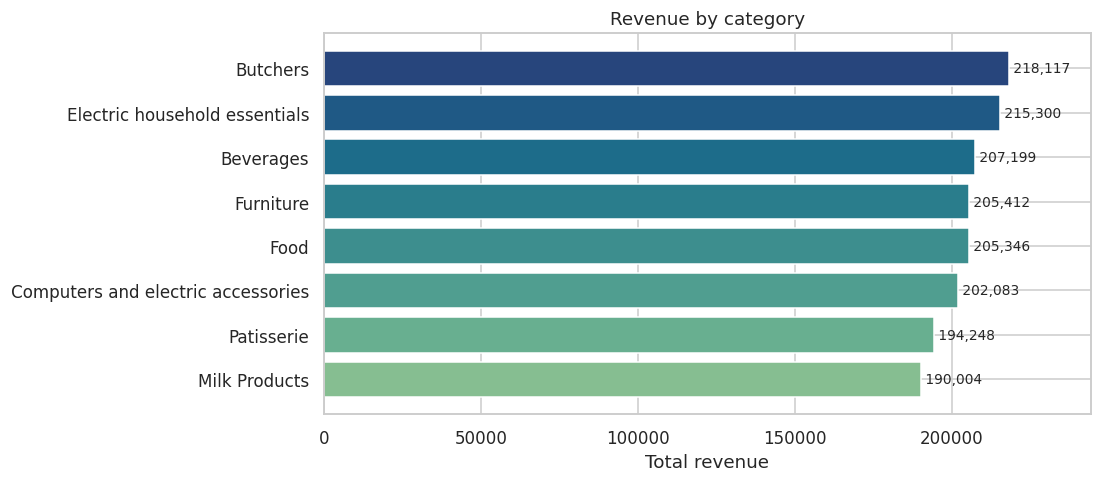

In [10]:
cat = eda.groupby("Category").agg(revenue=("Total Spent", "sum"),
                                  transactions=("Transaction ID", "count"),
                                  avg_transaction=("Total Spent", "mean"))
cat["share"] = cat["revenue"] / cat["revenue"].sum()
cat = cat.sort_values("revenue", ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
s = cat["revenue"].sort_values()
ax.barh(s.index, s.values, color=sns.color_palette("crest", len(s)))
for i, v in enumerate(s.values):
    ax.text(v, i, f" {v:,.0f}", va="center", fontsize=9)
ax.set_title("Revenue by category")
ax.set_xlabel("Total revenue")
ax.set_xlim(0, s.max() * 1.12)
fig.savefig("../images/revenue_by_category.png", dpi=150, bbox_inches="tight")

print(cat.assign(share=cat["share"].map("{:.1%}".format)).round(2).to_string())

### Monthly revenue trend

Average month: 44,744
Best month:  2022-01  (56,285)
Worst month: 2023-11  (38,676)

Revenue by full year:
Year
2022    540658.0
2023    515588.0
2024    554524.0


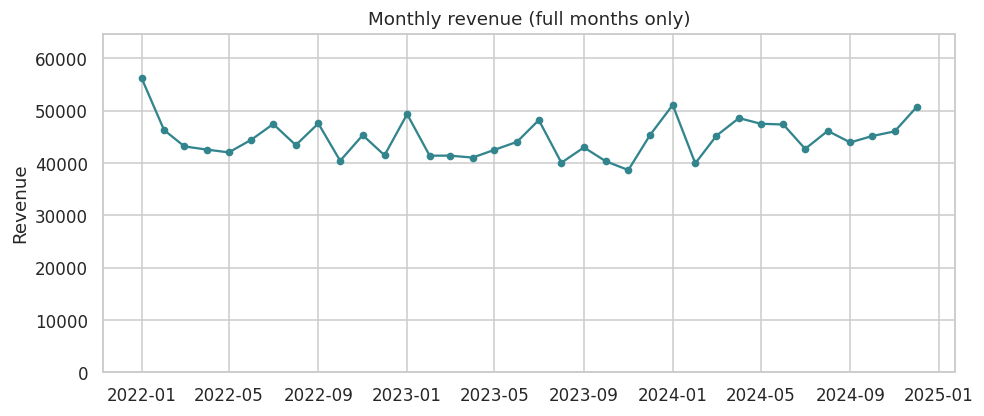

In [11]:
# 2025-01 is a partial month (data ends 18 Jan), so the trend uses full months only
monthly = (eda[eda["YearMonth"] < pd.Period("2025-01")]
           .groupby("YearMonth")["Total Spent"].sum())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index.to_timestamp(), monthly.values, marker="o", ms=4, color=sns.color_palette("crest", 3)[1])
ax.set_title("Monthly revenue (full months only)")
ax.set_ylabel("Revenue")
ax.set_ylim(0, monthly.max() * 1.15)
fig.savefig("../images/monthly_revenue.png", dpi=150, bbox_inches="tight")

print(f"Average month: {monthly.mean():,.0f}")
print(f"Best month:  {monthly.idxmax()}  ({monthly.max():,.0f})")
print(f"Worst month: {monthly.idxmin()}  ({monthly.min():,.0f})")
yearly = eda[eda['Year'] < 2025].groupby('Year')['Total Spent'].sum()
print("\nRevenue by full year:")
print(yearly.round(0).to_string())

### Seasonality by calendar month

Highest: Jan (52,249) | Lowest: Oct (41,989)
Spread between highest and lowest month: 24.4%


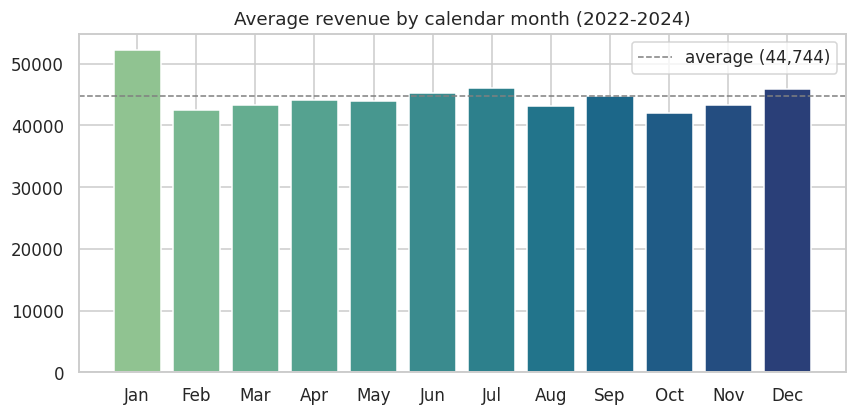

In [12]:
full = eda[eda["Year"].between(2022, 2024)]
season = full.groupby("Month")["Total Spent"].sum() / 3     # average over three full years
names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(names, season.values, color=sns.color_palette("crest", 12))
ax.axhline(season.mean(), color="grey", ls="--", lw=1, label=f"average ({season.mean():,.0f})")
ax.set_title("Average revenue by calendar month (2022-2024)")
ax.legend()
fig.savefig("../images/seasonality.png", dpi=150, bbox_inches="tight")

print(f"Highest: {names[season.idxmax()-1]} ({season.max():,.0f}) | Lowest: {names[season.idxmin()-1]} ({season.min():,.0f})")
print(f"Spread between highest and lowest month: {(season.max()/season.min()-1):.1%}")

### Payment method and location

                transactions   revenue  avg_transaction
Payment Method                                         
Cash                    4310  567469.5           131.66
Credit Card             4121  534509.0           129.70
Digital Wallet          4144  535730.5           129.28 

          transactions   revenue  avg_transaction
Location                                         
In-store          6221  805584.5           129.49
Online            6354  832124.5           130.96 


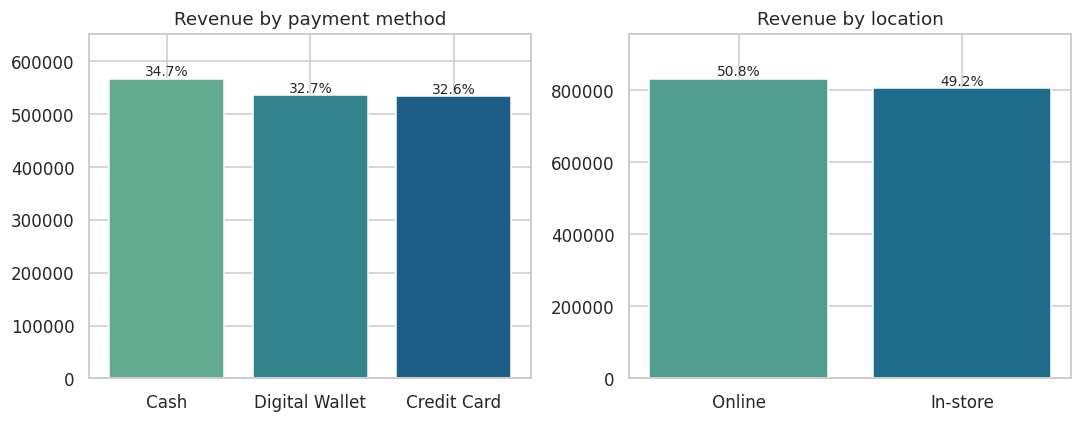

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["Payment Method", "Location"]):
    s = eda.groupby(col)["Total Spent"].sum().sort_values(ascending=False)
    ax.bar(s.index, s.values, color=sns.color_palette("crest", len(s)))
    ax.set_title(f"Revenue by {col.lower()}")
    ax.set_ylim(0, s.max() * 1.15)
    for i, v in enumerate(s.values):
        ax.text(i, v, f"{v / s.sum():.1%}", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig("../images/payment_location.png", dpi=150, bbox_inches="tight")

for col in ["Payment Method", "Location"]:
    g = eda.groupby(col).agg(transactions=("Transaction ID", "count"),
                             revenue=("Total Spent", "sum"),
                             avg_transaction=("Total Spent", "mean")).round(2)
    print(g.to_string(), "\n")

### Discounts

                  transactions  avg_spent  avg_quantity
Discount Applied                                       
False                     4157     130.84          5.60
True                      4219     131.01          5.56
UNKNOWN                   4199     128.86          5.52


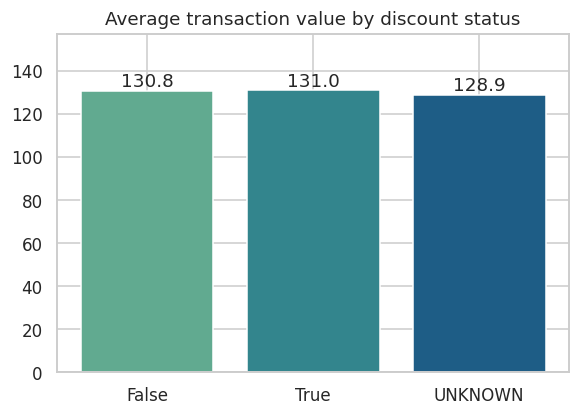

In [14]:
d = eda.groupby("Discount Applied").agg(transactions=("Transaction ID", "count"),
                                        avg_spent=("Total Spent", "mean"),
                                        avg_quantity=("Quantity", "mean")).round(2)
print(d.to_string())

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(d.index, d["avg_spent"], color=sns.color_palette("crest", len(d)))
ax.set_title("Average transaction value by discount status")
ax.set_ylim(0, d["avg_spent"].max() * 1.2)
for i, v in enumerate(d["avg_spent"]):
    ax.text(i, v, f"{v:,.1f}", ha="center", va="bottom")
fig.savefig("../images/discount.png", dpi=150, bbox_inches="tight")

### Top items

Item
Item_25_FUR     27101.0
Item_25_EHE     26732.0
Item_24_FUR     23740.0
Item_25_BUT     23657.0
Item_25_FOOD    22755.0
Item_22_BUT     22557.0
Item_23_BUT     22192.0
Item_19_MILK    21600.0
Item_23_EHE     21546.0
Item_19_CEA     21408.0


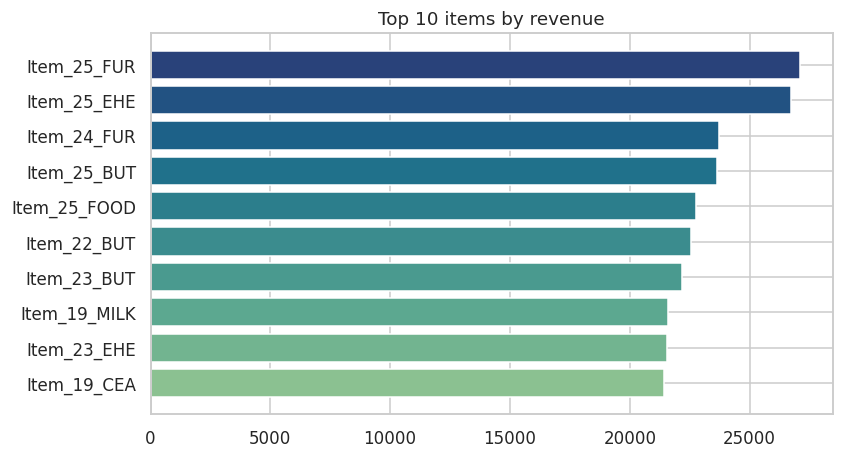

In [15]:
top = eda.groupby("Item")["Total Spent"].sum().nlargest(10).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top.values, color=sns.color_palette("crest", len(top)))
ax.set_title("Top 10 items by revenue")
fig.savefig("../images/top_items.png", dpi=150, bbox_inches="tight")
print(top.sort_values(ascending=False).round(0).to_string())

### Customers

Top customer: CUST_24 (71,942)
Lowest customer: CUST_25 (61,205)
Top 5 of 25 customers account for 21.4% of revenue (an even split would be 20.0%)
Revenue per customer: min 61,205, max 71,942


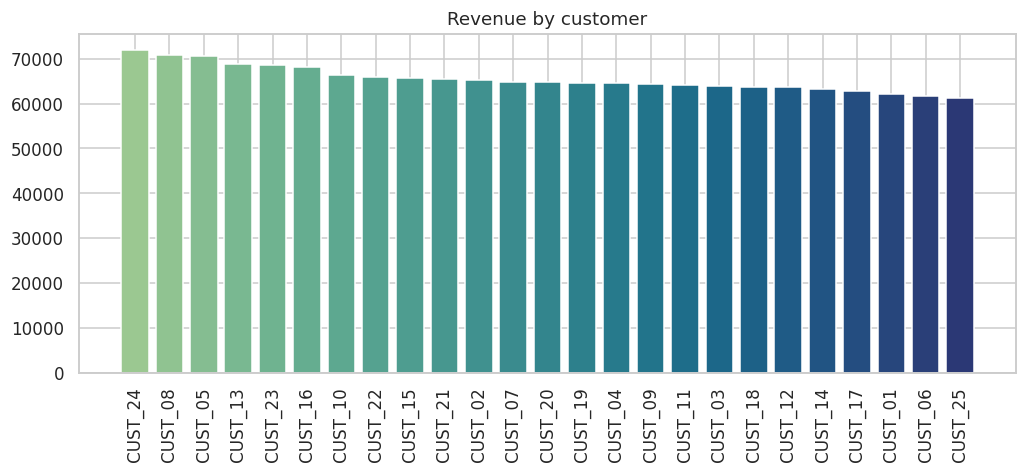

In [16]:
cust = eda.groupby("Customer ID").agg(revenue=("Total Spent", "sum"),
                                      transactions=("Transaction ID", "count")).sort_values("revenue", ascending=False)

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(cust.index, cust["revenue"], color=sns.color_palette("crest", len(cust)))
ax.set_title("Revenue by customer")
ax.tick_params(axis="x", rotation=90)
fig.savefig("../images/customers.png", dpi=150, bbox_inches="tight")

top5 = cust["revenue"].head(5).sum() / cust["revenue"].sum()
print(f"Top customer: {cust.index[0]} ({cust['revenue'].iloc[0]:,.0f})")
print(f"Lowest customer: {cust.index[-1]} ({cust['revenue'].iloc[-1]:,.0f})")
print(f"Top 5 of 25 customers account for {top5:.1%} of revenue (an even split would be 20.0%)")
print(f"Revenue per customer: min {cust['revenue'].min():,.0f}, max {cust['revenue'].max():,.0f}")

## 5. Assumptions and limitations

- **Quantity is estimated for 604 rows (4.8%).** Quantity and Total Spent were missing together, so they cannot be recovered. They are filled with the item-level average rounded up (5 to 7, mostly 6) and flagged in `Imputed_Flag`. Revenue figures that include these rows are approximate for that share.
- **Discount is unknown for 4,199 rows (33%).** They are labelled `UNKNOWN` rather than assumed to be "no discount", so any discount analysis covers only the known rows.
- **Prices are static and synthetic**, so price-driven analysis (elasticity, margin) isn't meaningful here.
- **The data is synthetic.** Patterns such as flat seasonality or near-equal customer spend likely reflect how it was generated, not real retail behaviour.
- **Item names are codes.** The dataset provides item codes (e.g. `Item_7_BEV`), not product names.